In [ ]:
# Download Bioclim vars from worldclim
!wget https://biogeo.ucdavis.edu/data/worldclim/v2.1/base/wc2.1_10m_bio.zip
!unzip /content/wc2.1_10m_bio.zip -d worldclim >> /dev/null

--2023-10-05 18:01:43--  https://biogeo.ucdavis.edu/data/worldclim/v2.1/base/wc2.1_10m_bio.zip
Resolving biogeo.ucdavis.edu (biogeo.ucdavis.edu)... 128.120.228.172
Connecting to biogeo.ucdavis.edu (biogeo.ucdavis.edu)|128.120.228.172|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://data.biogeo.ucdavis.edu/data/worldclim/v2.1/base/wc2.1_10m_bio.zip [following]
--2023-10-05 18:01:44--  https://data.biogeo.ucdavis.edu/data/worldclim/v2.1/base/wc2.1_10m_bio.zip
Resolving data.biogeo.ucdavis.edu (data.biogeo.ucdavis.edu)... 128.120.228.172
Connecting to data.biogeo.ucdavis.edu (data.biogeo.ucdavis.edu)|128.120.228.172|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 49869449 (48M) [application/zip]
Saving to: ‘wc2.1_10m_bio.zip’

wc2.1_10m_bio.zip   100%[===================>]  47.56M  14.5MB/s    in 3.3s    

2023-10-05 18:01:48 (14.5 MB/s) - ‘wc2.1_10m_bio.zip’ saved [49869449/49869449]



In [ ]:
!rm -rf *.tif

In [ ]:
!pip install rasterio >> /dev/null
!pip install geopandas >> /dev/null
!pip install soilgrids >> /dev/null
!pip install geopy >> /dev/null

In [ ]:
import pandas as pd
import geopandas as gpd
from rasterio.mask import mask
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import fiona
import os
import geopy
import numpy as np

import matplotlib.pyplot as plt
from soilgrids import SoilGrids

import warnings
from pathlib import Path

from rasterio.warp import calculate_default_transform, reproject, Resampling
target_crs = 'EPSG:4326'
# source_crs = dataset.crs

In [ ]:
# !rm -rf clips

In [ ]:

# Define the URL to the Natural Earth shapefile for Kenya
url = 'https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip'

# Read the shapefile using geopandas
gdf = gpd.read_file(url)

# Filter the data to extract the boundary for Kenya
kenya_boundary = gdf[gdf['ADMIN'] == 'Kenya']

# Save the Kenya boundary shapefile to a file
kenya_boundary.to_file('kenya_boundary.shp')


In [ ]:

bioclimatic_raster_names = [
    "bio_1", "bio_2", "bio_3", "bio_4", "bio_5", "bio_6", "bio_7", "bio_8", "bio_9",
    "bio_10", "bio_11", "bio_12", "bio_13", "bio_14", "bio_15", "bio_16", "bio_17",
    "bio_18", "bio_19"
]


raster_names = bioclimatic_raster_names

In [ ]:
def get_all_soilgrids_kenya():
  # List of soil variable IDs
  soil_variables = ["bdod", "cec", "cfvo", "clay", "nitrogen", "phh2o", "sand", "silt", "soc", "ocd", "wrb"]

  # get data from SoilGrids for each soil variable
  for variable in soil_variables:
      # Instantiate SoilGrids object
      soil_grids = SoilGrids()
      data = soil_grids.get_coverage_data(service_id=variable, coverage_id=f"{variable}_0-5cm_mean",
                                          west=3752140, south=-537527, east=4696291, north=685077,
                                          crs='urn:ogc:def:crs:EPSG::152160', output=f"soil/{variable}.tif")

      # show metadata
      for key, value in soil_grids.metadata.items():
          print('{}: {}'.format(key, value))


In [ ]:
# Download worldclim Rasters for Kenya

# Specify the path to the downloaded worldwide raster files
worldclim_folder = "/content/worldclim"
clipped_folder = "/content/clips"

# Specify the path to the shapefile containing the polygons
shapefile = "/content/kenya_boundary.shp"

# Read the polygons from the shapefile using GeoPandas
gdf = gpd.read_file(shapefile)

# Iterate over the bioclim rasters
for filename in os.listdir(worldclim_folder):
    if filename.endswith(".tif"):
        # Extract the bioclim number from the filename
        bioclim_number = filename.split("_")[-1].split(".")[0]

        # Read the worldwide raster file using Rasterio
        dataset = rasterio.open(os.path.join(worldclim_folder, filename))

        # Perform the clipping operation for each polygon
        for index, polygon in gdf.geometry.items():
            # Perform the clipping operation
            clipped_data, clipped_transform = mask(dataset, [polygon], crop=True)

            # Access the first dimension of the clipped data
            clipped_data = clipped_data[0]

            # Update the metadata of the clipped data
            clipped_meta = dataset.meta.copy()
            clipped_meta.update({
                "count": 1,  # Update the count to 1 since we have a single band
                "height": clipped_data.shape[0],
                "width": clipped_data.shape[1],
                "transform": clipped_transform
            })

            # Create the parent directories for the output file if they don't exist
            output_folder = os.path.join(clipped_folder, f"bio_{bioclim_number}")
            os.makedirs(output_folder, exist_ok=True)

            # Save the clipped data as a new raster file
            clipped_filename = f"bio_{bioclim_number}_Kenya.tif"
            clipped_filepath = os.path.join(output_folder, clipped_filename)
            with rasterio.open(clipped_filepath, "w", **clipped_meta) as dest:
                dest.write(clipped_data, indexes=1)

In [ ]:
class Raster(object):
    """
    Handles the loading and the patch extraction for a single raster
    """

    def __init__(self, path, country, size=256, nan=np.nan, out_of_bounds="error"):
        """Loads a GeoTIFF file containing an environmental raster

        Parameters
        ----------
        path : string / pathlib.Path
            Path to the folder containing all the rasters.
        country : string, either "FR" or "USA"
            Which country to load raster from.
        size : integer
            Size in pixels (size x size) of the patch to extract around each location.
        nan : float or None
            Value to use to replace missing data in original rasters, if None, leaves default values.
        out_of_bounds : string, either "error", "warn" or "ignore"
            If "error", raises an exception if the location requested is out of bounds of the rasters. Set to "warn" to only produces a warning and to "ignore" to silently ignore it and return a patch filled with missing data.
        """
        path = Path(path)
        if not path.exists():
            raise ValueError(
                "path should be the path to a raster, given non-existant path: {}".format(
                    path
                )
            )

        self.path = path
        self.name = path.name
        self.size = size
        self.out_of_bounds = out_of_bounds
        self.nan = nan

        # Loading the raster
        filename = path / "{}_{}.tif".format(self.name, country)
        print(filename)
        with rasterio.open(filename) as dataset:
            self.dataset = dataset
            self.raster = dataset.read(1).astype(np.float32)
            mask = self.dataset.read_masks(1).astype(bool)

        # Changes nodata to user specified value
        if nan:
            self.raster[np.isnan(self.raster)] = nan
            self.raster[~mask] = nan

        # setting the shape of the raster
        self.shape = self.raster.shape


    def _extract_patch(self, coordinates):
        """Extracts the patch around the given GPS coordinates.
        Avoid using this method directly.

        Parameter
        ----------
        coordinates : tuple containing two floats
            GPS coordinates (latitude, longitude)

        Returns
        -------
        patch : 2d array of floats, [size, size], or single float if size == 1
            Extracted patch around the given coordinates.
        """
        row, col = self.dataset.index(coordinates[1], coordinates[0])

        if self.size == 1:
            # Environmental vector
            patch = self.raster[row, col]
        else:
            # FIXME: can it happen that part of the patch is outside the raster? (and how about the mask of the dataset?)
            half_size = int(self.size / 2)
            # FIXME: only way to trigger an exception? (slices don't)
            self.raster[row, col]
            patch = self.raster[
                row - half_size:row + half_size,
                col - half_size:col + half_size
            ]

        patch = patch[np.newaxis]
        return patch

    def __len__(self):
        """Number of bands in the raster (should always be equal to 1).

        Returns
        -------
        n_bands : integer
            Number of bands in the raster
        """
        return self.dataset.count

    def __getitem__(self, coordinates):
        """Extracts the patch around the given GPS coordinates.

        Parameters
        ----------
        coordinates : tuple containing two floats
            GPS coordinates (latitude, longitude)

        Returns
        -------
        patch : 2d array of floats, [size, size], or single float if size == 1
            Extracted patch around the given coordinates.
        """
        try:
            return self._extract_patch(coordinates)
        except IndexError as e:
            if self.out_of_bounds == "error":
                raise e
            else:
                if self.out_of_bounds == "warn":
                    warnings.warn("GPS coordinates ({}, {}) out of bounds".format(*coordinates))

                if self.size == 1:
                    return np.array([self.nan], dtype=np.float32)
                else:
                    patch = np.empty((1, self.size, self.size), dtype=np.float32)
                    patch.fill(self.nan)
                    return patch

    def __repr__(self):
        return str(self)

    def __str__(self):
        return "name: " + self.name + "\n"

In [ ]:
class PatchExtractor(object):
    """
    Handles the loading and extraction of an environmental tensor from multiple rasters given GPS coordinates.
    """

    def __init__(self, root_path, country, size=256):
        """Constructor

        Parameters
        ----------
        root_path : string or pathlib.Path
            Path to the folder containing all the rasters.
        size : integer
            Size in pixels (size x size) of the patches to extract around each location.
        """
        self.root_path = Path(root_path)
        print("root_path:",self.root_path)
        if not self.root_path.exists():
            raise ValueError(
                "root_path should be the directory containing the rasters, given a non-existant path: {}".format(
                    root_path
                )
            )

        self.size = size

        #self.rasters_fr = []
        self.rasters_us = []
        self.country = "Kenya"

    def add_all_rasters(self, **kwargs):
        """Add all variables (rasters) available

        Parameters
        ----------
        kwargs : dict
            Updates the default arguments passed to Raster (nan, out_of_bounds, etc.)
        """
        for raster_name in raster_names:
            self.append(raster_name, **kwargs)

    def add_all_bioclimatic_rasters(self, **kwargs):
        """Add all bioclimatic variables (rasters) available

        Parameters
        ----------
        kwargs : dict
            Updates the default arguments passed to Raster (nan, out_of_bounds, etc.)
        """
        for raster_name in bioclimatic_raster_names:
            self.append(raster_name, **kwargs)

    def add_all_pedologic_rasters(self, **kwargs):
        """Add all pedologic variables (rasters) available

        Parameters
        ----------
        kwargs : dict
            Updates the default arguments passed to Raster (nan, out_of_bounds, etc.)
        """
        for raster_name in pedologic_raster_names:
            self.append(raster_name, **kwargs)

    def append(self, raster_name, **kwargs):
        """Loads and appends a single raster to the rasters already loaded.

        Can be useful to load only a subset of rasters or to pass configurations specific to each raster.

        Parameters
        ----------
        raster_name : string
            Name of the raster to load, should be a subfolder of root_path.
        kwargs : dict
            Updates the default arguments passed to Raster (nan, out_of_bounds, etc.)
        """

        r_us = Raster(self.root_path / raster_name, self.country, size=self.size, **kwargs)
        #r_fr = Raster(self.root_path / raster_name, "FR", size=self.size, **kwargs)

        self.rasters_us.append(r_us)
        #self.rasters_fr.append(r_fr)

    def clean(self):
        """Remove all rasters from the extractor.
        """
        #self.rasters_fr = []
        self.rasters_us = []

    def _get_rasters_list(self, coordinates):
        """Returns the list of rasters from the appropriate country

        Parameters
        ----------
        coordinates : tuple containing two floats
            GPS coordinates (latitude, longitude)

        Returns
        -------
        rasters : list of Raster objects
            All previously loaded rasters.
        """
        #if coordinates[1] > -10.0:
        #    return self.rasters_fr
        return(self.rasters_us)

    def __repr__(self):
        return str(self)

    def __str__(self):
        result = ""

        for rasters in [self.rasters_us]:
            for raster in rasters:
                result += "-" * 50 + "\n"
                result += str(raster)

        return result

    def __getitem__(self, coordinates):
        """Extracts the patches around the given GPS coordinates for all the previously loaded rasters.

        Parameters
        ----------
        coordinates : tuple containing two floats
            GPS coordinates (latitude, longitude)

        Returns
        -------
        patch : 3d array of floats, [n_rasters, size, size], or 1d array of floats, [n_rasters,], if size == 1
            Extracted patches around the given coordinates.
        """
        rasters = self._get_rasters_list(coordinates)
        return np.concatenate([r[coordinates] for r in rasters])

    def __len__(self):
        """Number of variables/rasters loaded.

        Returns
        -------
        n_rasters : integer
            Number of loaded rasters
        """
        return len(self.rasters_us)

    def plot(self, coordinates, return_fig=False, n_cols=5, fig=None, resolution=1.0):
        """Plot an environmental tensor (only works if size > 1)

        Parameters
        ----------
        coordinates : tuple containing two floats
            GPS coordinates (latitude, longitude)
        return_fig : boolean
            If True, returns the created plt.Figure object
        n_cols : integer
            Number of columns to use
        fig : plt.Figure or None
            If not None, use the given plt.Figure object instead of creating a new one
        resolution : float
            Resolution of the created figure

        Returns
        -------
        fig : plt.Figure
            If return_fig is True, the used plt.Figure object
        """
        if self.size <= 1:
            raise ValueError("Plot works only for tensors: size must be > 1")

        rasters = self._get_rasters_list(coordinates)

        # Metadata are the name of the variables and the bounding boxes in latitude-longitude coordinates
        metadata = [
            (
                raster.name,
                [
                    coordinates[1] - (self.size // 2) * raster.dataset.res[0],
                    coordinates[1] + (self.size // 2) * raster.dataset.res[0],
                    coordinates[0] - (self.size // 2) * raster.dataset.res[1],
                    coordinates[0] + (self.size // 2) * raster.dataset.res[1],
                ],
            )
            for raster in rasters
        ]

        # Extracts the patch
        patch = self[coordinates]

        # Computing number of rows and columns
        n_rows = (patch.shape[0] + (n_cols - 1)) // n_cols

        if fig is None:
            fig = plt.figure(figsize=(n_cols * 6.4 * resolution, n_rows * 4.8 * resolution))

        axes = fig.subplots(n_rows, n_cols)
        axes = axes.ravel()

        for i, (ax, k) in enumerate(zip(axes, metadata)):
            p = np.squeeze(patch[i])
            im = ax.imshow(p, extent=k[1], aspect="equal", interpolation="none")

            ax.set_title(k[0], fontsize=20)
            fig.colorbar(im, ax=ax)

        for ax in axes[len(metadata):]:
            ax.axis("off")

        fig.tight_layout()

        if return_fig:
            return fig

In [ ]:
DATA_PATH = '/content/clips'
extractor = PatchExtractor(DATA_PATH, country="Kenya", size = 200)

root_path: /content/clips


In [ ]:
extractor.add_all_rasters()

/content/clips/bio_1/bio_1_Kenya.tif
/content/clips/bio_2/bio_2_Kenya.tif
/content/clips/bio_3/bio_3_Kenya.tif
/content/clips/bio_4/bio_4_Kenya.tif
/content/clips/bio_5/bio_5_Kenya.tif
/content/clips/bio_6/bio_6_Kenya.tif
/content/clips/bio_7/bio_7_Kenya.tif
/content/clips/bio_8/bio_8_Kenya.tif
/content/clips/bio_9/bio_9_Kenya.tif
/content/clips/bio_10/bio_10_Kenya.tif
/content/clips/bio_11/bio_11_Kenya.tif
/content/clips/bio_12/bio_12_Kenya.tif
/content/clips/bio_13/bio_13_Kenya.tif
/content/clips/bio_14/bio_14_Kenya.tif
/content/clips/bio_15/bio_15_Kenya.tif
/content/clips/bio_16/bio_16_Kenya.tif
/content/clips/bio_17/bio_17_Kenya.tif
/content/clips/bio_18/bio_18_Kenya.tif
/content/clips/bio_19/bio_19_Kenya.tif


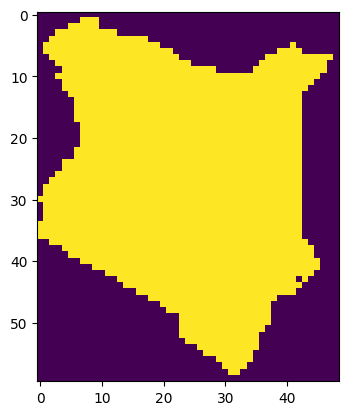

In [ ]:
with rasterio.open("/content/clips/bio_16/bio_16_Kenya.tif") as src:
  plt.imshow(src.read(1))

In [ ]:
rasterio.open("/content/clips/bio_19/bio_19_Kenya.tif").shape

(60, 49)

In [ ]:
lat, long = -1.3920, 37.9633

patch = extractor[lat, long]

print("Patch shape: {}".format(patch.shape))
print("Data type: {}".format(patch.dtype))

Patch shape: (19, 60, 49)
Data type: float32


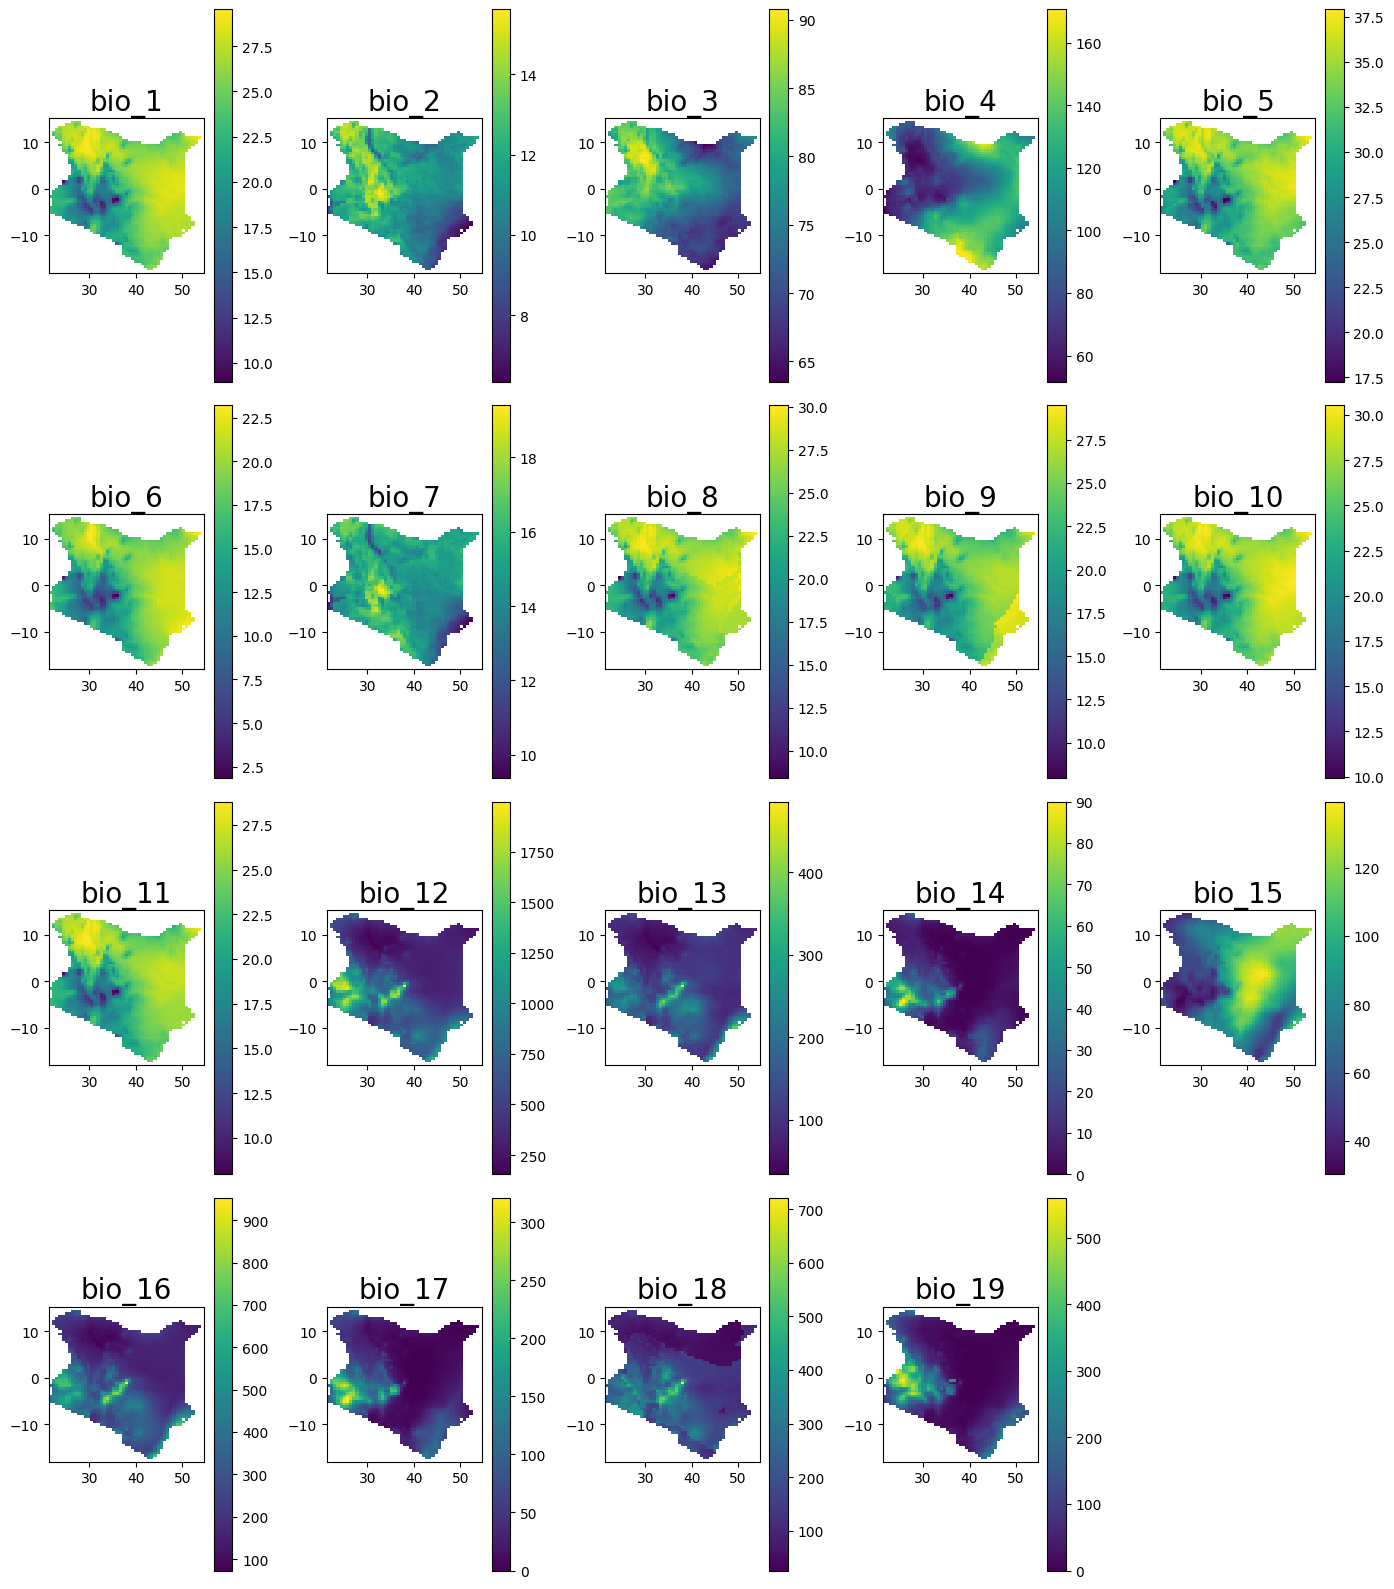

In [ ]:
fig = plt.figure(figsize=(14, 16))
extractor.plot((lat, long), fig=fig)

In [ ]:
extractor = PatchExtractor(DATA_PATH, country="Kenya", size = 1)
extractor.add_all_rasters()
print("Number of rasters: {}".format(len(extractor)))

root_path: /content/clips
/content/clips/bio_1/bio_1_Kenya.tif
/content/clips/bio_2/bio_2_Kenya.tif
/content/clips/bio_3/bio_3_Kenya.tif
/content/clips/bio_4/bio_4_Kenya.tif
/content/clips/bio_5/bio_5_Kenya.tif
/content/clips/bio_6/bio_6_Kenya.tif
/content/clips/bio_7/bio_7_Kenya.tif
/content/clips/bio_8/bio_8_Kenya.tif
/content/clips/bio_9/bio_9_Kenya.tif
/content/clips/bio_10/bio_10_Kenya.tif
/content/clips/bio_11/bio_11_Kenya.tif
/content/clips/bio_12/bio_12_Kenya.tif
/content/clips/bio_13/bio_13_Kenya.tif
/content/clips/bio_14/bio_14_Kenya.tif
/content/clips/bio_15/bio_15_Kenya.tif
/content/clips/bio_16/bio_16_Kenya.tif
/content/clips/bio_17/bio_17_Kenya.tif
/content/clips/bio_18/bio_18_Kenya.tif
/content/clips/bio_19/bio_19_Kenya.tif
Number of rasters: 19


In [ ]:
!zip -r kenya_environment_rasters kenya_environment_rasters

  adding: kenya_environment_rasters/ (stored 0%)
  adding: kenya_environment_rasters/bio_6/ (stored 0%)
  adding: kenya_environment_rasters/bio_6/bio_6_Kenya.tif (deflated 51%)
  adding: kenya_environment_rasters/bio_2/ (stored 0%)
  adding: kenya_environment_rasters/bio_2/bio_2_Kenya.tif (deflated 48%)
  adding: kenya_environment_rasters/bio_4/ (stored 0%)
  adding: kenya_environment_rasters/bio_4/bio_4_Kenya.tif (deflated 46%)
  adding: kenya_environment_rasters/bio_14/ (stored 0%)
  adding: kenya_environment_rasters/bio_14/bio_14_Kenya.tif (deflated 85%)
  adding: kenya_environment_rasters/bio_18/ (stored 0%)
  adding: kenya_environment_rasters/bio_18/bio_18_Kenya.tif (deflated 74%)
  adding: kenya_environment_rasters/bio_15/ (stored 0%)
  adding: kenya_environment_rasters/bio_15/bio_15_Kenya.tif (deflated 47%)
  adding: kenya_environment_rasters/bio_13/ (stored 0%)
  adding: kenya_environment_rasters/bio_13/bio_13_Kenya.tif (deflated 76%)
  adding: kenya_environment_rasters/bio_9/ 